# 00 — FoodVision AI | Full Dataset Preparation, Cleaning, EDA & Split Audit

This is the **self-contained source notebook** for the Food-270 inspection, duplicate audit, cleaning decisions, manifest, reproducible 70/15/15 splits, and EDA figures. The algorithms below were consolidated from the original `ml/src/*.py` files.

**Default mode is read-only:** all heavy dataset rescans and split regeneration are disabled unless you explicitly opt in. The committed splits and 270-class mapping remain untouched, protecting the pretrained checkpoint and backend. The original image dataset is never modified.

**Notebook demonstration:** execute all cells to display saved-data statistics, charts and images. Enable full rebuild separately only if you need to reproduce the preprocessing pipeline, which can take substantial disk I/O.


## 1. Configure paths

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import csv, json, random, shutil, hashlib, io
from statistics import mean, median

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, UnidentifiedImageError

DATASET_ROOT = Path(r"C:\deep_learning_projects\archive\images")
current = Path.cwd()
PROJECT_ROOT = next((p for p in (current, *current.parents)
                     if (p / 'ml/data/splits/train.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Cannot locate foodvision-ai/ml/data/splits/train.csv')
DATA_DIR = PROJECT_ROOT / 'ml' / 'data'
SPLITS_DIR = DATA_DIR / 'splits'
FIGURES_DIR = PROJECT_ROOT / 'ml' / 'figures'
EXPERIMENT_DIR = DATA_DIR / '_mentor_rebuild'   # never overwrite trained production splits

# Default: safe demonstration; leave all four switches False for Run All.
RUN_FULL_AUDIT = False
REBUILD_CLEAN_MANIFEST = False
RECREATE_SPLITS = False
EXPORT_FIGURES = False

print('Dataset root:', DATASET_ROOT, '| exists:', DATASET_ROOT.is_dir())
print('Project root:', PROJECT_ROOT)
print('Split files:', SPLITS_DIR)
print('Read-only demonstration mode:', not any([
    RUN_FULL_AUDIT, REBUILD_CLEAN_MANIFEST, RECREATE_SPLITS, EXPORT_FIGURES
]))
assert DATASET_ROOT.is_dir(), 'Check DATASET_ROOT'


Dataset root: C:\deep_learning_projects\archive\images | exists: True
Project root: C:\deep_learning_projects\foodvision-ai
Split files: C:\deep_learning_projects\foodvision-ai\ml\data\splits
Read-only demonstration mode: True


## 2. Inspect the original dataset (code formerly in `inspect_dataset.py` and `explore_structure.py`)

The full inspection uses Pillow to check decode integrity and SHA-256 to find exact duplicate bytes; it can be slow for 229k+ images. Existing `dataset_summary.json` is used by default, and the image files are never changed.

In [2]:
SUPPORTED_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()

    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()

def inspect_dataset(root: Path) -> dict:
    if not root.is_dir():
        raise ValueError(f"Dataset directory not found: {root}")

    class_dirs = sorted(
        (path for path in root.iterdir() if path.is_dir()),
        key=lambda path: path.name,
    )

    if not class_dirs:
        raise ValueError("No class folders found")

    class_counts = {}
    formats = Counter()
    widths = []
    heights = []
    corrupt = []
    unsupported = []
    hashes = defaultdict(list)

    for class_dir in class_dirs:
        valid_count = 0

        for path in sorted(class_dir.iterdir()):
            if not path.is_file():
                continue

            if path.suffix.lower() not in SUPPORTED_EXTENSIONS:
                unsupported.append(str(path.relative_to(root)))
                continue

            relative_path = str(path.relative_to(root))

            try:
                with Image.open(path) as image:
                    image.verify()

                with Image.open(path) as image:
                    image.load()
                    width, height = image.size
                    image_format = image.format or "unknown"

                widths.append(width)
                heights.append(height)
                formats[image_format] += 1
                hashes[sha256_file(path)].append(relative_path)
                valid_count += 1

            except (
                OSError,
                ValueError,
                UnidentifiedImageError,
            ) as error:
                corrupt.append({
                    "path": relative_path,
                    "reason": str(error),
                })

        class_counts[class_dir.name] = valid_count
        print(f"{class_dir.name}: {valid_count} valid images", flush=True)

    duplicates = [
        paths
        for paths in hashes.values()
        if len(paths) > 1
    ]

    total_valid = sum(class_counts.values())

    return {
        "total_classes": len(class_dirs),
        "total_valid_images": total_valid,
        "class_counts": class_counts,
        "image_formats": dict(formats),
        "image_dimensions": {
            "min_width": min(widths) if widths else None,
            "max_width": max(widths) if widths else None,
            "min_height": min(heights) if heights else None,
            "max_height": max(heights) if heights else None,
        },
        "corrupt_images": corrupt,
        "unsupported_files": unsupported,
        "duplicate_groups": duplicates,
    }

def save_reports(result: dict, output_dir: Path) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)

    summary_path = output_dir / "dataset_summary.json"
    summary_path.write_text(
        json.dumps(result, indent=2),
        encoding="utf-8",
    )

    class_counts_path = output_dir / "class_distribution.csv"

    with class_counts_path.open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.writer(file)
        writer.writerow(["class_name", "valid_images"])

        for class_name, count in sorted(
            result["class_counts"].items()
        ):
            writer.writerow([class_name, count])

    print(f"\nReports saved to: {output_dir}")

# Lightweight structure preview, replacing explore_structure.py
folders = sorted(p for p in DATASET_ROOT.iterdir() if p.is_dir())
print('Food class folders:', len(folders))
print('First 10 classes:', [p.name for p in folders[:10]])

if RUN_FULL_AUDIT:
    original_audit = inspect_dataset(DATASET_ROOT)
    save_reports(original_audit, EXPERIMENT_DIR)
    print('Rebuilt audit saved to:', EXPERIMENT_DIR)
else:
    audit_path = DATA_DIR / 'dataset_summary.json'
    with audit_path.open(encoding='utf-8') as f:
        original_audit = json.load(f)
    print('Using saved audit:', audit_path)
print('Reported valid images:', original_audit['total_valid_images'])
print('Corrupt images:', len(original_audit['corrupt_images']))
print('Exact duplicate groups:', len(original_audit['duplicate_groups']))


Food class folders: 270
First 10 classes: ['adana_kebab', 'apple', 'apple_pie', 'apricot', 'asparagus', 'avocado', 'ayran', 'baby_back_ribs', 'bacon', 'bagel']
Using saved audit: C:\deep_learning_projects\foodvision-ai\ml\data\dataset_summary.json
Reported valid images: 229245
Corrupt images: 0
Exact duplicate groups: 3371


## 3. Examine duplicate groups (formerly `analyze_duplicates.py`)

Same-class duplicate groups retain one deterministic copy; cross-class identical images are excluded completely to prevent ambiguous training labels.

In [3]:
duplicate_groups = original_audit['duplicate_groups']
same_class_groups = sum(len({Path(p).parts[0] for p in group}) == 1 for group in duplicate_groups)
cross_class_groups = len(duplicate_groups) - same_class_groups
redundant_copies = sum(len(group) - 1 for group in duplicate_groups)
print('Duplicate groups:', len(duplicate_groups))
print('Same-class groups:', same_class_groups)
print('Cross-class groups:', cross_class_groups)
print('Redundant copies:', redundant_copies)
for group in [g for g in duplicate_groups if len({Path(p).parts[0] for p in g}) > 1][:3]:
    print('Cross-class example:', group)


Duplicate groups: 3371
Same-class groups: 3072
Cross-class groups: 299
Redundant copies: 3509
Cross-class example: ['Cauliflower_recipes\\1113.jpg', 'Cauliflower_recipes\\21.jpg', 'chickpea_dish\\100.jpg']
Cross-class example: ['Cauliflower_recipes\\karnabahar0000.jpg', 'cauliflower\\karnabahar0000.jpg']
Cross-class example: ['Cauliflower_recipes\\karnabahar0001.jpg', 'cauliflower\\karnabahar0001.jpg']


## 4. Clean manifest creation (formerly `create_clean_manifest.py`)

Cleaning excludes corrupt files, drops every exact duplicate with conflicting labels, and retains only one deterministic same-class copy. **By default the existing manifest is read, not regenerated.** Optional regeneration writes under `_mentor_rebuild` instead of overwriting the committed production splits.

In [4]:
def normalize(path: str) -> str:
    return path.replace('\\', '/')

EXTENSIONS = SUPPORTED_EXTENSIONS

def create_manifest(
    dataset_path: Path,
    report_path: Path,
    output_dir: Path,
) -> dict:
    if not dataset_path.is_dir():
        raise ValueError(f"Dataset not found: {dataset_path}")

    with report_path.open("r", encoding="utf-8") as file:
        report = json.load(file)

    corrupt = {
        normalize(item["path"])
        for item in report["corrupt_images"]
    }

    same_class_excluded = set()
    cross_class_excluded = set()

    for group in report["duplicate_groups"]:
        paths = sorted(normalize(p) for p in group)
        classes = {path.split("/")[0] for path in paths}

        if len(classes) > 1:
            # Ambiguous labels: exclude the complete group.
            cross_class_excluded.update(paths)
        else:
            # Same label: retain one deterministic copy.
            same_class_excluded.update(paths[1:])

    class_counts = Counter()
    clean_rows = []
    actual_valid_count = 0

    class_dirs = sorted(
        (path for path in dataset_path.iterdir() if path.is_dir()),
        key=lambda p: p.name,
    )

    for class_dir in class_dirs:
        for image_path in sorted(class_dir.iterdir()):
            if not image_path.is_file():
                continue

            if image_path.suffix.lower() not in EXTENSIONS:
                continue

            relative = image_path.relative_to(
                dataset_path
            ).as_posix()

            if relative in corrupt:
                continue

            actual_valid_count += 1

            if relative in cross_class_excluded:
                continue

            if relative in same_class_excluded:
                continue

            clean_rows.append((class_dir.name, relative))
            class_counts[class_dir.name] += 1

    expected_count = report["total_valid_images"]

    if actual_valid_count != expected_count:
        raise ValueError(
            "Dataset no longer matches the inspection report. "
            f"Expected {expected_count}, found {actual_valid_count}. "
            "Run the dataset inspection again."
        )

    output_dir.mkdir(parents=True, exist_ok=True)

    manifest_path = output_dir / "clean_manifest.csv"

    with manifest_path.open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.writer(file)
        writer.writerow(["class_name", "relative_path"])
        writer.writerows(clean_rows)

    summary = {
        "original_valid_images": actual_valid_count,
        "same_class_copies_excluded": len(same_class_excluded),
        "ambiguous_cross_class_files_excluded": len(
            cross_class_excluded
        ),
        "clean_images": len(clean_rows),
        "classes_with_images": len(class_counts),
        "class_counts": dict(sorted(class_counts.items())),
    }

    summary_path = output_dir / "clean_manifest_summary.json"
    summary_path.write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8",
    )

    return summary

if REBUILD_CLEAN_MANIFEST:
    rebuild_report = EXPERIMENT_DIR / 'dataset_summary.json'
    if not rebuild_report.exists():
        raise FileNotFoundError('Enable RUN_FULL_AUDIT first, or provide the rebuilt inspection report')
    rebuilt_manifest_summary = create_manifest(DATASET_ROOT, rebuild_report, EXPERIMENT_DIR)
    print('Rebuilt manifest:', EXPERIMENT_DIR / 'clean_manifest.csv')
else:
    with (DATA_DIR / 'clean_manifest_summary.json').open(encoding='utf-8') as f:
        clean_summary = json.load(f)
    print('Using saved clean manifest:', DATA_DIR / 'clean_manifest.csv')
    print('Clean images:', clean_summary['clean_images'])
    print('Food classes:', clean_summary['classes_with_images'])


Using saved clean manifest: C:\deep_learning_projects\foodvision-ai\ml\data\clean_manifest.csv
Clean images: 225437
Food classes: 270


## 5. Reproducible splits (formerly `create_splits.py`)

The per-class split is deterministic (seed 42) and checks disjointness. The optional rebuild writes to `_mentor_rebuild/splits` and **never changes** the committed `ml/data/splits/` files used by your production model.

In [5]:
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
SEED = 42
from pathlib import PurePosixPath

def load_manifest(manifest_path: Path) -> dict:
    class_images = defaultdict(list)
    seen_paths = set()

    with manifest_path.open(
        "r", newline="", encoding="utf-8"
    ) as file:
        reader = csv.DictReader(file)

        required = {"class_name", "relative_path"}
        if not required.issubset(reader.fieldnames or []):
            raise ValueError("Invalid manifest columns")

        for row in reader:
            class_name = row["class_name"]
            relative_path = row["relative_path"].replace("\\", "/")

            parts = PurePosixPath(relative_path).parts

            if (
                not class_name
                or not relative_path
                or not parts
                or parts[0] != class_name
                or ".." in parts
                or relative_path.startswith("/")
            ):
                raise ValueError(
                    f"Invalid manifest entry: {relative_path}"
                )

            if relative_path in seen_paths:
                raise ValueError(
                    f"Duplicate image path: {relative_path}"
                )

            seen_paths.add(relative_path)
            class_images[class_name].append(relative_path)

    if not class_images:
        raise ValueError("Manifest contains no images")

    return class_images

def save_csv(path: Path, rows: list):
    with path.open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.writer(file)
        writer.writerow(
            ["relative_path", "class_name", "class_index"]
        )
        writer.writerows(rows)

def create_splits(
    manifest_path: Path,
    output_dir: Path,
    seed: int = SEED,
) -> dict:
    class_images = load_manifest(manifest_path)

    class_names = sorted(class_images)
    class_to_index = {
        name: index
        for index, name in enumerate(class_names)
    }

    rng = random.Random(seed)

    splits = {
        "train": [],
        "val": [],
        "test": [],
    }

    per_class_counts = {}

    for class_name in class_names:
        images = sorted(class_images[class_name])
        rng.shuffle(images)

        total = len(images)

        n_train = round(total * TRAIN_RATIO)
        n_val = round(total * VAL_RATIO)
        n_test = total - n_train - n_val

        if min(n_train, n_val, n_test) < 1:
            raise ValueError(
                f"Too few images in class: {class_name}"
            )

        partitions = {
            "train": images[:n_train],
            "val": images[n_train:n_train + n_val],
            "test": images[n_train + n_val:],
        }

        for split_name, paths in partitions.items():
            for relative_path in paths:
                splits[split_name].append(
                    (
                        relative_path,
                        class_name,
                        class_to_index[class_name],
                    )
                )

        per_class_counts[class_name] = {
            "train": n_train,
            "val": n_val,
            "test": n_test,
        }

    train_paths = {row[0] for row in splits["train"]}
    val_paths = {row[0] for row in splits["val"]}
    test_paths = {row[0] for row in splits["test"]}

    assert train_paths.isdisjoint(val_paths)
    assert train_paths.isdisjoint(test_paths)
    assert val_paths.isdisjoint(test_paths)

    total_images = sum(len(rows) for rows in splits.values())

    assert len(train_paths | val_paths | test_paths) == total_images
    assert total_images == sum(map(len, class_images.values()))

    output_dir.mkdir(parents=True, exist_ok=True)

    for name, rows in splits.items():
        save_csv(output_dir / f"{name}.csv", rows)

    (output_dir / "class_to_index.json").write_text(
        json.dumps(class_to_index, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

    summary = {
        "seed": seed,
        "train_ratio": TRAIN_RATIO,
        "val_ratio": VAL_RATIO,
        "test_ratio": 1 - TRAIN_RATIO - VAL_RATIO,
        "total_classes": len(class_names),
        "total_images": total_images,
        "train_images": len(splits["train"]),
        "val_images": len(splits["val"]),
        "test_images": len(splits["test"]),
        "per_class_counts": per_class_counts,
    }

    (output_dir / "split_summary.json").write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8",
    )

    return summary

if RECREATE_SPLITS:
    rebuild_manifest = EXPERIMENT_DIR / 'clean_manifest.csv'
    if not rebuild_manifest.is_file():
        raise FileNotFoundError('First generate a clean manifest in _mentor_rebuild')
    rebuilt_splits = create_splits(rebuild_manifest, EXPERIMENT_DIR / 'splits', seed=SEED)
    print('Rebuilt independent splits:', rebuilt_splits['total_images'])
else:
    print('Using committed train/val/test splits at:', SPLITS_DIR)


Using committed train/val/test splits at: C:\deep_learning_projects\foodvision-ai\ml\data\splits


## 6. Validate manifests and duplicate leakage (formerly `validate_splits.py`)

This validates that every cleaned image appears exactly once and that exact duplicates do not cross splits. This complements the faster path and class-index checks later.

In [7]:
SPLIT_NAMES = ("train", "val", "test")

def normalize(path):
    return str(path).replace("\\", "/")
def validate_splits(report_path, manifest_path, splits_dir):
    # Load the original duplicate analysis.
    with report_path.open("r", encoding="utf-8") as file:
        report = json.load(file)

    # Load the cleaned manifest.
    manifest = {}

    with manifest_path.open(
        "r", newline="", encoding="utf-8"
    ) as file:
        for row in csv.DictReader(file):
            path = normalize(row["relative_path"])
            if path in manifest:
                raise ValueError(f"Duplicate manifest path: {path}")
            manifest[path] = row["class_name"]

    # Load the actual train/val/test partitions.
    assignments = {}
    split_counts = {}

    for split_name in SPLIT_NAMES:
        path = splits_dir / f"{split_name}.csv"

        with path.open(
            "r", newline="", encoding="utf-8"
        ) as file:
            rows = list(csv.DictReader(file))

        split_counts[split_name] = len(rows)

        for row in rows:
            relative = normalize(row["relative_path"])

            if relative in assignments:
                raise ValueError(
                    f"Path appears more than once: {relative}"
                )

            assignments[relative] = (
                split_name,
                row["class_name"],
            )

    # Every cleaned image must appear exactly once.
    if set(assignments) != set(manifest):
        raise ValueError(
            "Split paths do not match the clean manifest"
        )

    for path, (_, label) in assignments.items():
        if label != manifest[path]:
            raise ValueError(
                f"Class label mismatch: {path}"
            )

    # Validate using the prior SHA-256 duplicate audit.
    groups_checked = 0

    for group in report["duplicate_groups"]:
        paths = [normalize(path) for path in group]

        retained = [
            path for path in paths if path in assignments
        ]

        # A cleaned dataset must retain at most one
        # file from any exact-duplicate group.
        if len(retained) > 1:
            raise ValueError(
                f"Exact duplicate content retained: {retained}"
            )

        # Cross-class conflicts must be excluded entirely.
        classes = {
            path.split("/")[0] for path in paths
        }

        if len(classes) > 1 and retained:
            raise ValueError(
                f"Cross-class duplicate retained: {retained}"
            )

        groups_checked += 1

    summary = {
        "total_images": len(assignments),
        "train_images": split_counts["train"],
        "val_images": split_counts["val"],
        "test_images": split_counts["test"],
        "duplicate_groups_checked": groups_checked,
        "duplicate_conflicts": 0,
    }

    return summary

validation = validate_splits(
    DATA_DIR / 'dataset_summary.json',
    DATA_DIR / 'clean_manifest.csv',
    SPLITS_DIR,
)
print('Split validation:', validation)


Split validation: {'total_images': 225437, 'train_images': 157800, 'val_images': 33813, 'test_images': 33824, 'duplicate_groups_checked': 3371, 'duplicate_conflicts': 0}


## 7. Reusable EDA statistics and optional chart export (formerly `visualize_dataset.py`)

The class counts and statistics are reproduced directly below. The existing inline plots later in this notebook are sufficient for mentor review, so `ml/figures/` is not required. Switch on `EXPORT_FIGURES` only if you want fresh PNG/JSON copies.

In [8]:
def visualize_dataset(summary_path: Path, output_dir: Path):
    with summary_path.open("r", encoding="utf-8") as file:
        summary = json.load(file)

    class_counts = summary["class_counts"]

    if not class_counts:
        raise ValueError("No classes found in the summary.")

    output_dir.mkdir(parents=True, exist_ok=True)

    sorted_classes = sorted(
        class_counts.items(),
        key=lambda item: item[1],
        reverse=True,
    )

    counts = list(class_counts.values())

    statistics = {
        "total_classes": len(class_counts),
        "total_images": sum(counts),
        "minimum_images_per_class": min(counts),
        "maximum_images_per_class": max(counts),
        "mean_images_per_class": round(mean(counts), 2),
        "median_images_per_class": median(counts),
        "classes_below_100": sum(c < 100 for c in counts),
        "classes_below_500": sum(c < 500 for c in counts),
        "top_15_classes": sorted_classes[:15],
        "bottom_15_classes": sorted_classes[-15:],
    }

    # Plot 1: Top 15 classes
    top = sorted_classes[:15]

    fig, ax = plt.subplots(figsize=(11, 7))
    ax.barh(
        [item[0] for item in reversed(top)],
        [item[1] for item in reversed(top)],
    )
    ax.set_title("Top 15 Food Categories by Image Count")
    ax.set_xlabel("Number of Images")
    fig.tight_layout()
    fig.savefig(output_dir / "top_15_classes.png", dpi=150)
    plt.close(fig)

    # Plot 2: Bottom 15 classes
    bottom = sorted(
        class_counts.items(),
        key=lambda item: item[1],
    )[:15]

    fig, ax = plt.subplots(figsize=(11, 7))
    ax.barh(
        [item[0] for item in reversed(bottom)],
        [item[1] for item in reversed(bottom)],
    )
    ax.set_title("Bottom 15 Food Categories by Image Count")
    ax.set_xlabel("Number of Images")
    fig.tight_layout()
    fig.savefig(output_dir / "bottom_15_classes.png", dpi=150)
    plt.close(fig)

    # Plot 3: Distribution across all classes
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.hist(counts, bins=30, edgecolor="black")
    ax.set_title("Food-270 Class Distribution")
    ax.set_xlabel("Images per Class")
    ax.set_ylabel("Number of Classes")
    fig.tight_layout()
    fig.savefig(output_dir / "class_distribution.png", dpi=150)
    plt.close(fig)

    stats_path = output_dir / "eda_statistics.json"

    stats_path.write_text(
        json.dumps(statistics, indent=2),
        encoding="utf-8",
    )

    print("\nFOOD-270 EDA RESULTS")
    print("=" * 45)

    for key, value in statistics.items():
        if key not in {"top_15_classes", "bottom_15_classes"}:
            print(f"{key}: {value}")

    print("\nTop 15 classes:")
    for name, count in sorted_classes[:15]:
        print(f"  {name}: {count}")

    print("\nBottom 15 classes:")
    for name, count in bottom:
        print(f"  {name}: {count}")

    print(f"\nReports saved to: {output_dir}")

if EXPORT_FIGURES:
    visualize_dataset(DATA_DIR / 'clean_manifest_summary.json', FIGURES_DIR)
else:
    print('Figure export disabled. Charts display inline below.')


Figure export disabled. Charts display inline below.


## 8. Random image gallery utility (formerly `visualize_samples.py`)

The later EDA section already shows samples directly in the notebook. This reusable function remains available if you want to export the gallery again.

In [9]:
def create_sample_gallery(
    dataset_path: Path,
    manifest_path: Path,
    output_path: Path,
    seed: int = 42,
):
    class_images = defaultdict(list)

    with manifest_path.open(
        "r", newline="", encoding="utf-8"
    ) as file:
        reader = csv.DictReader(file)

        for row in reader:
            class_images[row["class_name"]].append(
                row["relative_path"]
            )

    rng = random.Random(seed)

    available_classes = sorted(class_images)
    selected_classes = rng.sample(
        available_classes,
        min(12, len(available_classes)),
    )

    fig, axes = plt.subplots(3, 4, figsize=(14, 11))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, class_name in zip(axes, selected_classes):
        relative_path = rng.choice(
            sorted(class_images[class_name])
        )

        image_path = dataset_path / relative_path

        with Image.open(image_path) as image:
            image = ImageOps.exif_transpose(image)
            image = image.convert("RGB")
            image.thumbnail((350, 350))

            ax.imshow(image)

        ax.set_title(
            class_name.replace("_", " "),
            fontsize=11,
        )
        ax.axis("off")

    fig.suptitle(
        "Food-270: Sample Images from Clean Manifest",
        fontsize=16,
    )

    fig.tight_layout(rect=(0, 0, 1, 0.96))

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    fig.savefig(output_path, dpi=150)
    plt.close(fig)

    print(f"Gallery saved to: {output_path}")
    print(f"Classes shown: {len(selected_classes)}")

if EXPORT_FIGURES:
    create_sample_gallery(DATASET_ROOT, DATA_DIR / 'clean_manifest.csv', FIGURES_DIR / 'sample_gallery.png')


## 2. Read the existing cleaned dataset splits

In [10]:
splits = {name: pd.read_csv(SPLITS_DIR / f'{name}.csv')
          for name in ('train', 'val', 'test')}
required = {'relative_path', 'class_name', 'class_index'}
for name, df in splits.items():
    assert required.issubset(df.columns), f'{name}: missing required columns'
    assert df[list(required)].notna().all().all(), f'{name}: null values'
    print(f'{name:5s}: {len(df):,} images, {df.class_name.nunique()} classes')
print('Total selected/clean images:', sum(map(len, splits.values())))

train: 157,800 images, 270 classes
val  : 33,813 images, 270 classes
test : 33,824 images, 270 classes
Total selected/clean images: 225437


## 3. Class distribution (EDA)

Train examples per class:
count     270.0
mean      584.4
std       300.5
min        46.0
25%       402.0
50%       700.0
75%       700.0
max      2124.0


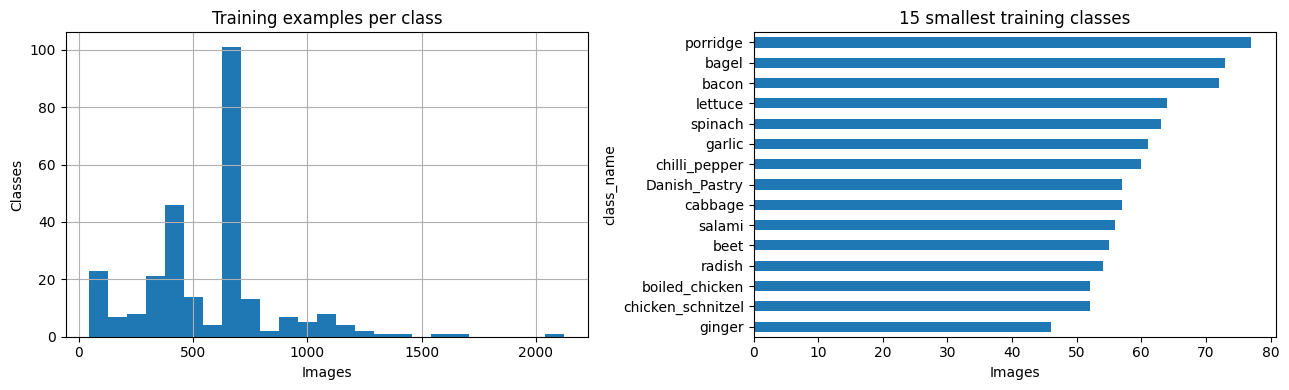

In [11]:
train_counts = splits['train'].class_name.value_counts()
print('Train examples per class:')
print(train_counts.describe().round(1).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
train_counts.hist(bins=25, ax=axes[0])
axes[0].set(title='Training examples per class', xlabel='Images', ylabel='Classes')
train_counts.sort_values().head(15).plot.barh(ax=axes[1])
axes[1].set(title='15 smallest training classes', xlabel='Images')
plt.tight_layout(); plt.show()

## 4. Confirm mapping, leakage and split consistency

In [12]:
with (SPLITS_DIR / 'class_to_index.json').open(encoding='utf-8') as f:
    class_to_index = json.load(f)
print('Mapped food classes:', len(class_to_index))
assert len(class_to_index) == 270, 'Unexpected number of classes'
for name, df in splits.items():
    expected = df.class_name.map(class_to_index)
    assert expected.notna().all(), f'{name}: class missing from mapping'
    assert (expected.astype(int) == df.class_index).all(), f'{name}: class index mismatch'
    assert df.relative_path.is_unique, f'{name}: duplicate relative paths'
paths = {k: set(v.relative_path.str.replace('\\', '/', regex=False)) for k, v in splits.items()}
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    common = paths[a] & paths[b]
    print(f'{a}/{b} shared file paths:', len(common))
    assert not common, f'Leakage by relative file path: {a}/{b}'
print('Checks passed (path-level only; near-duplicates require separate image-hash analysis).')

Mapped food classes: 270
train/val shared file paths: 0
train/test shared file paths: 0
val/test shared file paths: 0
Checks passed (path-level only; near-duplicates require separate image-hash analysis).


## 5. Check missing images (can scan all 225k paths)

In [13]:
missing = []
for name, df in splits.items():
    for rel in df.relative_path:
        file = DATASET_ROOT / Path(str(rel).replace('\\', '/'))
        if not file.is_file():
            missing.append((name, str(rel)))
print('Missing image files:', len(missing))
print('Examples:', missing[:10])
assert not missing, 'Fix missing image paths before training'

Missing image files: 0
Examples: []


## 6. Display reproducible random samples

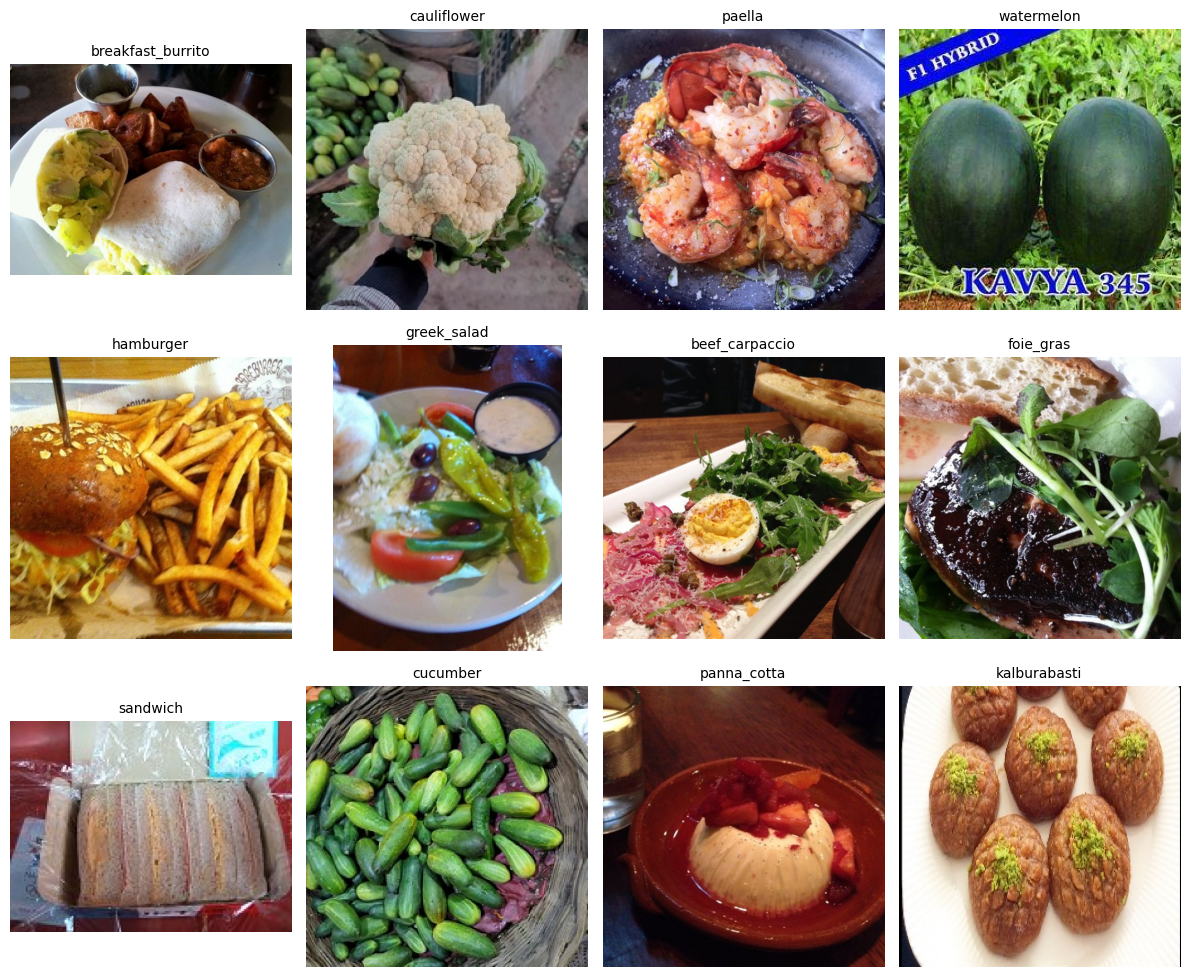

In [14]:
items = splits['train'].sample(n=12, random_state=42)
fig, axes = plt.subplots(3, 4, figsize=(12, 10))
for ax, row in zip(axes.flat, items.itertuples(index=False)):
    p = DATASET_ROOT / Path(str(row.relative_path).replace('\\', '/'))
    try:
        with Image.open(p) as img:
            ax.imshow(ImageOps.exif_transpose(img).convert('RGB'))
        ax.set_title(str(row.class_name), fontsize=10)
    except Exception as exc:
        ax.text(.05, .5, f'Could not read image:\\n{exc}', transform=ax.transAxes)
    ax.axis('off')
plt.tight_layout(); plt.show()

## 7. Image format and resolution audit (random sample; no image modification)

format
JPEG    500
Name: count, dtype: int64
        width  height
count   500.0   500.0
mean    407.0   368.1
std     296.4   215.9
min     115.0   120.0
25%     256.0   256.0
50%     400.0   320.0
75%     512.0   512.0
max    6240.0  4160.0


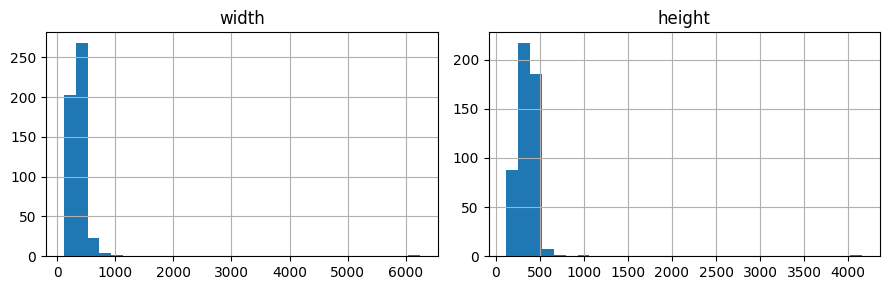

In [15]:
sample = splits['train'].sample(n=min(500, len(splits['train'])), random_state=42)
rows=[]
for rel in sample.relative_path:
    p=DATASET_ROOT / Path(str(rel).replace('\\', '/'))
    try:
        with Image.open(p) as im:
            rows.append({'format': im.format, 'width':im.width, 'height':im.height})
    except Exception:
        rows.append({'format':'UNREADABLE', 'width':None, 'height':None})
image_stats=pd.DataFrame(rows)
print(image_stats['format'].value_counts(dropna=False))
print(image_stats[['width','height']].describe().round(1))
image_stats[['width','height']].hist(figsize=(9,3), bins=30)
plt.tight_layout();plt.show()

## Existing production split metadata

`ml/data/splits/` already contains the committed five reproducibility files. No migration or copying is needed; do not regenerate these production splits just to produce notebook outputs.

In [16]:
for name in ('train.csv', 'val.csv', 'test.csv', 'class_to_index.json', 'split_summary.json'):
    path = SPLITS_DIR / name
    assert path.is_file(), f'Missing required production metadata: {path}'
    print(f'{name}: {path.stat().st_size:,} bytes')
print('Production split metadata is present and unchanged.')


train.csv: 6,501,038 bytes
val.csv: 1,392,003 bytes
test.csv: 1,393,842 bytes
class_to_index.json: 5,896 bytes
split_summary.json: 23,873 bytes
Production split metadata is present and unchanged.


## Cleanup checklist — only after verifying the project

- The dataset inspection, cleaning, split creation, validation, duplicates summary, class distribution and sample gallery code now lives in **this notebook**. No generated charts need to be tracked in `ml/figures/`.
- **Keep** original Food-270 images, `ml/data/clean_manifest.csv`, `ml/data/clean_manifest_summary.json`, `ml/data/dataset_summary.json`, and all five `ml/data/splits/` files. They are required for auditing and reproducibility.
- The training notebooks already contain their own TensorFlow dataset decoder/loader. Confirm their dependencies and run `python -m pytest ml/tests -q` **before** deleting `ml/src/` scripts: tests may still import those modules. Migrate any tests to the notebook-independent equivalent or retain a small reusable module for them.
- `ml/figures/` may be deleted after you rerun the EDA notebook and save the inline figures, provided no other script or notebook loads the PNGs or EDA JSON. Set `EXPORT_FIGURES=False` so running this notebook does not recreate that folder.
- Do not delete `ml/experiments/efficientnet_b0/best_finetuned_weights.h5`: the FastAPI backend uses it.
- Regenerating splits can change the class mapping or order if the dataset changes; never overwrite production split files while preparing a mentor demonstration.
